## Arrays, numeric types and sparse matrices

Everything in MATLAB is an array. This notebook indexes arrays by condition, stacks them into three dimensions, looks at the numeric types besides `double`, and stores a large matrix that is mostly zeros.

### Logical indexing

A comparison gives a logical array of the same size; indexing with it picks out the elements where it is true. `find` gives their positions.

In [ ]:
M = magic(5)
big = M(M > 20)'
M(mod(M, 2) == 0) = 0
[r, c] = find(M == 25)


M =

    17    24     1     8    15
    23     5     7    14    16
     4     6    13    20    22
    10    12    19    21     3
    11    18    25     2     9




big =

    23    24    25    21    22


M =

    17     0     1     0    15
    23     5     7     0     0
     0     0    13     0     0
     0     0    19    21     3
    11     0    25     0     9


r =

     5


c =

     3



### N-dimensional arrays

A third index stacks matrices into pages. Reductions take a dimension: `sum(A, 3)` adds the pages together.

In [ ]:
A = cat(3, [1 2; 3 4], [10 20; 30 40], [100 200; 300 400]);
size(A)
page_sums = squeeze(sum(A, [1 2]))'
across_pages = sum(A, 3)
permuted_size = size(permute(A, [3 1 2]))


ans =

     2     2     3


page_sums =

          10         100        1000


across_pages =

   111   222
   333   444


permuted_size =

     3     2     2



### Integer and single precision

Integer types round to the nearest integer and saturate at their limits instead of wrapping around. `single` keeps about 7 significant digits, `double` about 16: `eps` is the gap from 1 to the next number. Combining `single` with `double` gives `single`.

In [ ]:
a = int8(100) + int8(100)
b = int8(-7) / int8(2)
c = uint8(250):uint8(255)
limits = [intmin('int16'), intmax('int16')]
fprintf('eps: single %g, double %g\n', eps('single'), eps('double'))
fprintf('1/3 in single %.17f\n1/3 in double %.17f\n', single(1)/3, 1/3)
mixed = class([single(1), 2])


a =

  int8

   127


b =

  int8

   -4


c =

  1×6 uint8 row vector

   250   251   252   253   254   255


limits =

  1×2 int16 row vector

   -32768    32767

eps: single 1.19209e-07, double 2.22045e-16
1/3 in single 0.33333334326744080
1/3 in double 0.33333333333333331

mixed =

    'single'



### Sparse matrices

The second-difference matrix of a fine grid is tridiagonal: almost all zeros. `spdiags` builds it storing only the nonzeros, and backslash solves with it quickly. Here it solves the boundary-value problem $-u'' = 1$, $u(0) = u(1) = 0$, whose solution is $u = x(1 - x)/2$.

2000 x 2000 with 5998 nonzeros (0.150% of the entries)



max_error =

   3.5347e-14



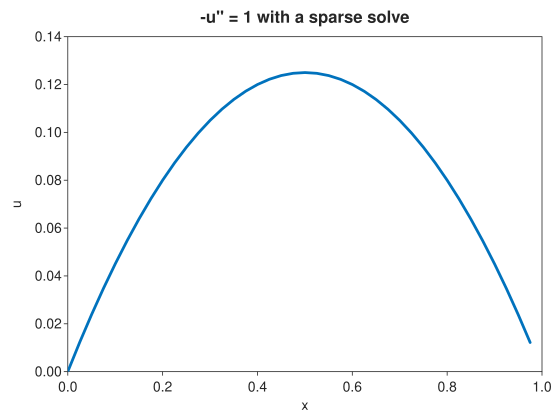

In [ ]:
figure
n = 2000;
h = 1 / (n + 1);
e = ones(n, 1);
T = spdiags([-e, 2*e, -e], -1:1, n, n) / h^2;
fprintf('%d x %d with %d nonzeros (%.3f%% of the entries)\n', n, n, nnz(T), 100 * nnz(T) / n^2)
xs = (1:n)' * h;
u = T \ ones(n, 1);
max_error = max(abs(u - xs .* (1 - xs) / 2))
plot(xs(1:50:end), u(1:50:end), 'LineWidth', 1.5), xlabel('x'), ylabel('u'), title('-u'''' = 1 with a sparse solve')

*Topics after examples in MatRust-Studio (MIT license); the code here is Sagebrush's own.*